# Dhrystone results

Plots `results/dhrystone.csv` written by `benchmark/benchmark.py` (or `container_run_benchmark.sh`).

- x axis: number of cores, one line per quantum and mode
- modes: `sync` (one Pydrofoil per hart, dlmopen), `sync, shared` (`shared_pydrofoil=true`), `async, rate N`
- only runs with status `ok` are used; with several iterations the mean is plotted with the standard deviation as error bars
- the figures are also saved to `results/plots/` (set `SAVE = False` to skip)

Needs pandas and matplotlib.

In [46]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

CSV_NAME = 'results/dhrystone.csv'
SAVE = True


def find_csv(name):
    # the notebook may be started from the repo root or from benchmark/
    for base in (Path.cwd(), *Path.cwd().parents):
        if (base / name).is_file():
            return base / name
    raise FileNotFoundError('%s not found from %s' % (name, Path.cwd()))


CSV = find_csv(CSV_NAME)
PLOT_DIR = CSV.parent / 'plots'
if SAVE:
    PLOT_DIR.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (9, 5.5), 'axes.grid': True, 'grid.alpha': 0.4})
CSV

PosixPath('/scratch/seibt/vcml-pydrofoil/results/dhrystone.csv')

## Load the runs

In [47]:
raw = pd.read_csv(CSV, keep_default_na=False, na_values=[''])
bad = raw[raw['status'] != 'ok']
print('%d runs, %d not ok (ignored)' % (len(raw), len(bad)))
if len(bad):
    display(bad[['timestamp', 'n_cores', 'quantum', 'async', 'async_rate', 'shared',
                 'status', 'exit_code', 'log']])

df = raw[raw['status'] == 'ok'].copy()
for col in ('async', 'shared'):
    df[col] = df[col].astype(str).str.lower() == 'true'
df['async_rate'] = df['async_rate'].fillna(0).astype(int)

def mode(row):
    m = "sync" if row["async"] is False else "async, rate %d" % row["async_rate"]
    return m + ", shared" if str(row.get("shared", "false")).lower() == "true" else m


df['mode'] = df.apply(mode, axis=1)
df['mips_per_core'] = df['mips'] / df['n_cores']


def quantum_seconds(q):
    for unit, factor in (('ns', 1e-9), ('us', 1e-6), ('ms', 1e-3), ('s', 1)):
        if q.endswith(unit):
            return float(q[:-len(unit)]) * factor
    return float(q)


def mode_key(m):
    return ({'sync': 0, 'sync, shared': 1}.get(m, 2), m)


QUANTA = sorted(df['quantum'].unique(), key=quantum_seconds)
MODES = sorted(df['mode'].unique(), key=mode_key)
CORES = sorted(df['n_cores'].unique())
COLORS = {m: 'C%d' % i for i, m in enumerate(MODES)}
LINESTYLES = ['-', '--', ':', '-.']

df[['n_cores', 'quantum', 'mode', 'iteration', 'wall_time', 'runtime', 'mips',
    'instructions']].sort_values(['n_cores', 'quantum', 'mode'], key=lambda s: s.map(
        {'mode': mode_key, 'quantum': quantum_seconds}.get(s.name, lambda v: v)))

36 runs, 0 not ok (ignored)


,n_cores,quantum,mode,iteration,wall_time,runtime,mips,instructions
0,1,1us,sync,1,1.41,1.2392,61.7,76448000
1,1,1us,sync,2,1.36,1.2710,60.1,76448000
2,1,1us,sync,3,1.31,1.2453,61.4,76448000
3,1,1us,"sync, shared",1,1.31,1.2399,61.7,76448000
4,1,1us,"sync, shared",2,1.31,1.2466,61.3,76448000
5,1,1us,"sync, shared",3,1.36,1.2609,60.6,76448000
6,1,1us,"async, rate 5",1,2.76,2.6656,28.7,76448801
7,1,1us,"async, rate 5",2,2.36,2.2659,33.7,76448801
8,1,1us,"async, rate 5",3,2.71,2.6125,29.3,76448801
9,2,1us,sync,1,2.56,2.4195,63.2,152904000


## Plot helper

In [48]:
def plot_metric(metric, ylabel, title, logy=False):
    fig, ax = plt.subplots()
    for qi, q in enumerate(QUANTA):
        for m in MODES:
            d = df[(df['quantum'] == q) & (df['mode'] == m)]
            if d.empty:
                continue
            s = d.groupby('n_cores')[metric].agg(['mean', 'std', 'count'])
            label = m if len(QUANTA) == 1 else '%s, %s' % (q, m)
            ax.errorbar(s.index, s['mean'], yerr=s['std'].fillna(0), marker='o', capsize=4,
                        color=COLORS[m], linestyle=LINESTYLES[qi % len(LINESTYLES)], label=label)
    ax.set_xscale('log', base=2)
    ax.set_xticks(CORES)
    ax.set_xticklabels(CORES)
    ax.set_xlabel('Cores')
    ax.set_ylabel(ylabel)
    if logy:
        ax.set_yscale('log')
    else:
        ax.set_ylim(bottom=0)
    quanta = '' if len(QUANTA) != 1 else ' (quantum %s)' % QUANTA[0]
    ax.set_title(title + quanta)
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
    fig.tight_layout()
    if SAVE:
        path = PLOT_DIR / ('dhrystone_%s.png' % metric)
        fig.savefig(path, dpi=200, bbox_inches='tight')
        print('wrote', path)
    plt.show()

## Simulation speed

wrote /scratch/seibt/vcml-pydrofoil/results/plots/dhrystone_mips.png


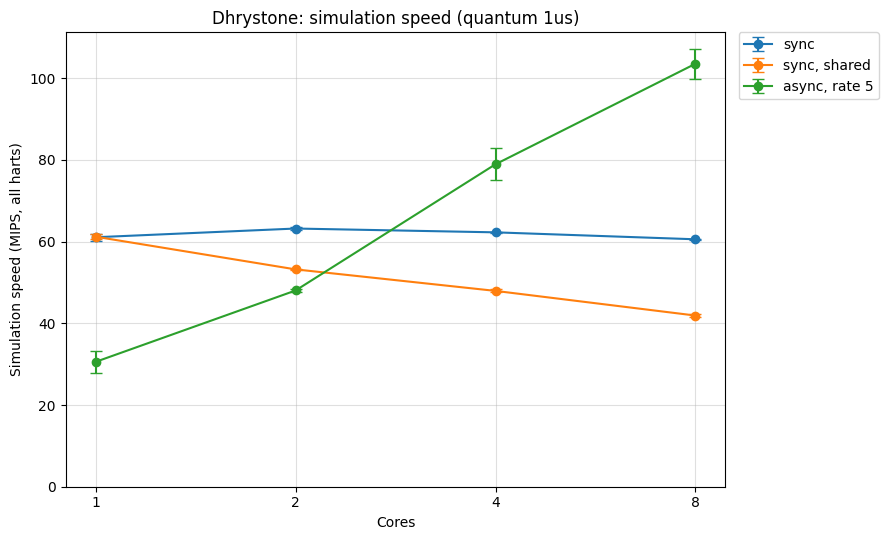

In [49]:
plot_metric('mips', 'Simulation speed (MIPS, all harts)', 'Dhrystone: simulation speed')

wrote /scratch/seibt/vcml-pydrofoil/results/plots/dhrystone_mips_per_core.png


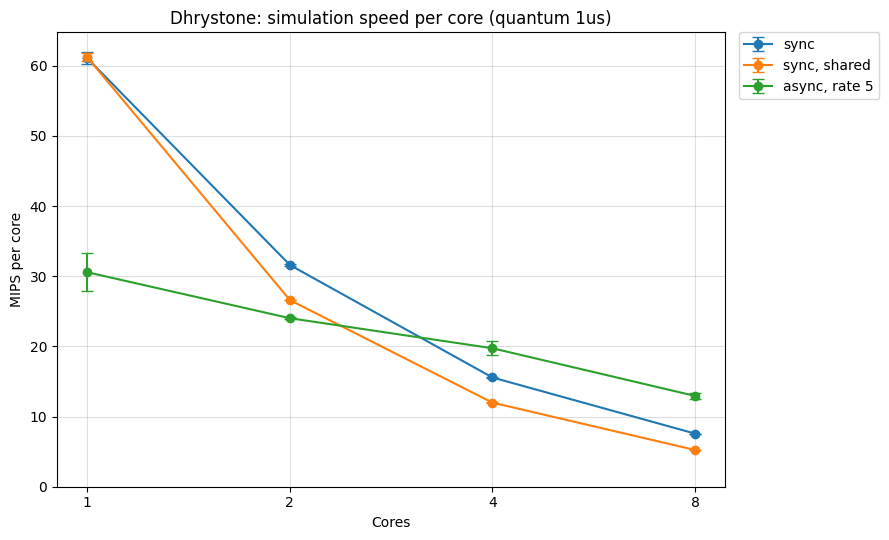

In [50]:
plot_metric('mips_per_core', 'MIPS per core', 'Dhrystone: simulation speed per core')

## Runtime

wrote /scratch/seibt/vcml-pydrofoil/results/plots/dhrystone_runtime.png


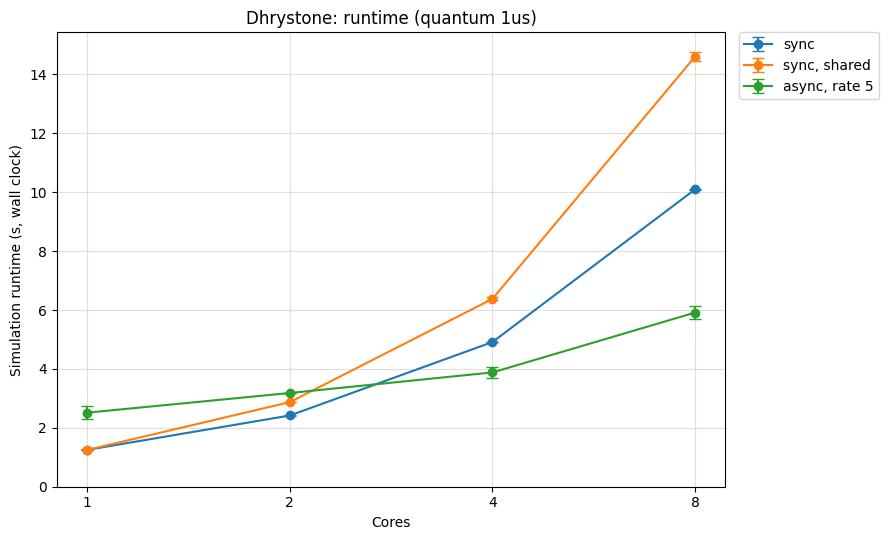

In [51]:
plot_metric('runtime', 'Simulation runtime (s, wall clock)', 'Dhrystone: runtime')

## Speedup against `sync`

Mean runtime of `sync` (one Pydrofoil per hart) divided by the mean runtime of each mode, per core count and quantum. Above 1 means faster than `sync`.

mode             sync, shared  async, rate 5
quantum n_cores                             
1us     1                1.00           0.50
        2                0.84           0.76
        4                0.77           1.27
        8                0.69           1.71

wrote /scratch/seibt/vcml-pydrofoil/results/plots/dhrystone_speedup_1us.png


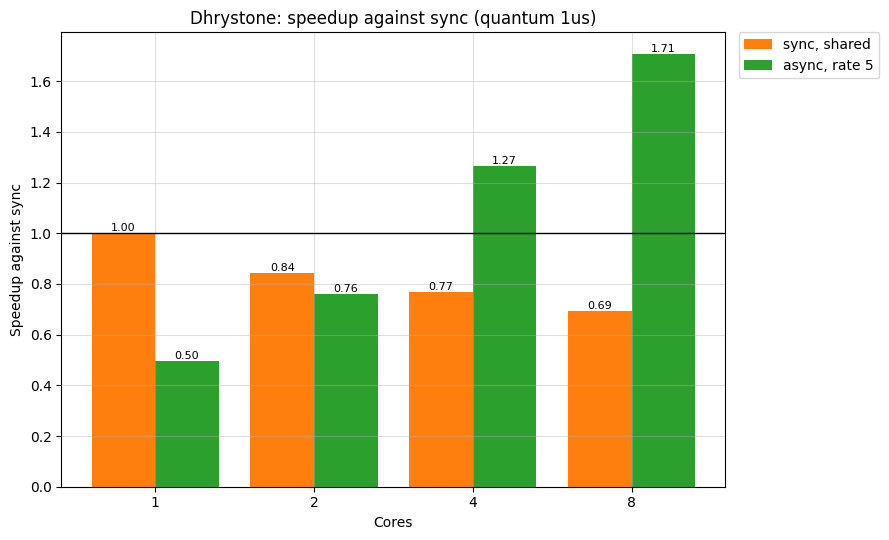

In [52]:
mean_rt = df.groupby(['quantum', 'n_cores', 'mode'])['runtime'].mean().unstack('mode')
if 'sync' not in mean_rt:
    print('no sync runs in the CSV, no speedup to compute')
else:
    speedup = mean_rt.rdiv(mean_rt['sync'], axis=0)[[m for m in MODES if m != 'sync']]
    display(speedup.round(2))
    for q in QUANTA:
        sq = speedup.loc[q]
        fig, ax = plt.subplots()
        width = 0.8 / max(len(sq.columns), 1)
        for i, m in enumerate(sq.columns):
            xs = [x + (i - (len(sq.columns) - 1) / 2) * width for x in range(len(sq.index))]
            bars = ax.bar(xs, sq[m], width, color=COLORS[m], label=m)
            ax.bar_label(bars, fmt='%.2f', fontsize=8)
        ax.axhline(1, color='black', linewidth=1)
        ax.set_xticks(range(len(sq.index)))
        ax.set_xticklabels(sq.index)
        ax.set_xlabel('Cores')
        ax.set_ylabel('Speedup against sync')
        ax.set_title('Dhrystone: speedup against sync (quantum %s)' % q)
        ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
        fig.tight_layout()
        if SAVE:
            path = PLOT_DIR / ('dhrystone_speedup_%s.png' % q)
            fig.savefig(path, dpi=200, bbox_inches='tight')
            print('wrote', path)
        plt.show()

## Memory

`max_rss_mb` is the peak resident memory of the VP process (`ru_maxrss` of `wait4`, see
`benchmark/README.md`). RSS counts a page once per mapping: with one Pydrofoil per hart
(`dlmopen`) the library code is mapped once per hart, so RSS overstates what an extra hart
really costs. Runs from before the column existed have it empty and are left out.


36 of 36 runs with max_rss_mb
wrote /scratch/seibt/vcml-pydrofoil/results/plots/dhrystone_max_rss_mb.png


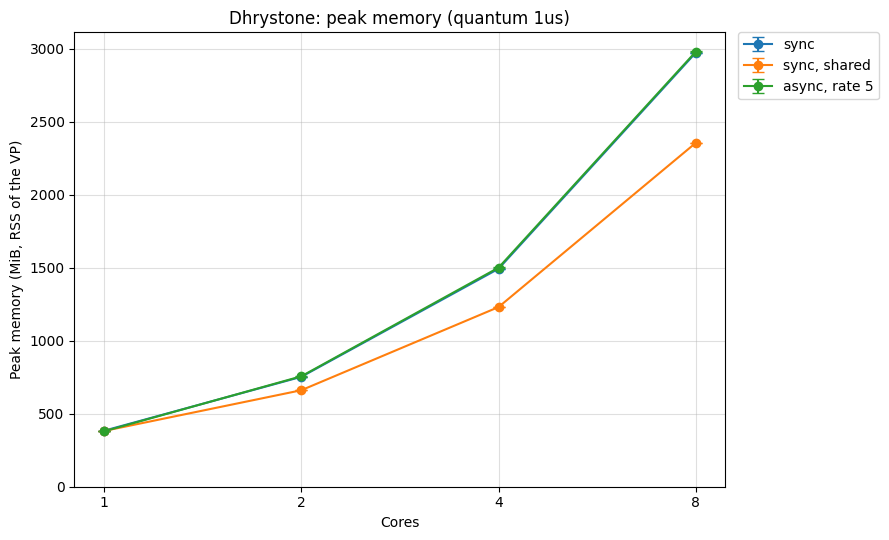

In [53]:
mem = df.dropna(subset=['max_rss_mb']).copy() if 'max_rss_mb' in df else df.iloc[0:0]
print('%d of %d runs with max_rss_mb' % (len(mem), len(df)))
mem['max_rss_per_core'] = mem['max_rss_mb'] / mem['n_cores']


def plot_memory(metric, ylabel, title):
    # plot_metric works on df, so hand it the runs with a memory value
    global df
    df, saved = mem, df
    try:
        plot_metric(metric, ylabel, title)
    finally:
        df = saved


if not mem.empty:
    plot_memory('max_rss_mb', 'Peak memory (MiB, RSS of the VP)', 'Dhrystone: peak memory')


wrote /scratch/seibt/vcml-pydrofoil/results/plots/dhrystone_max_rss_per_core.png


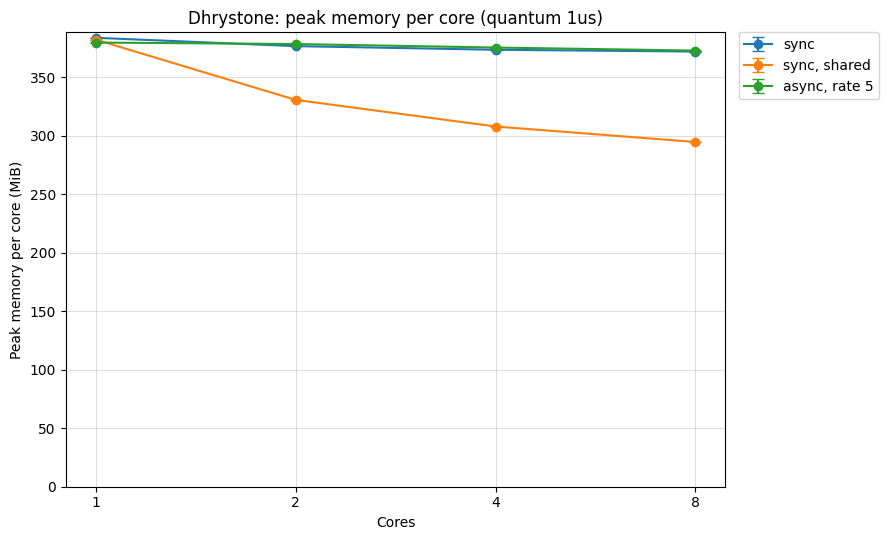

In [54]:
if not mem.empty:
    plot_memory('max_rss_per_core', 'Peak memory per core (MiB)', 'Dhrystone: peak memory per core')


### Memory saved by `shared`

Mean peak memory of `sync` (one Pydrofoil per hart) against `sync, shared` (one Pydrofoil for
all harts), per core count and quantum.


sync (MiB)  shared (MiB)  saved (MiB)  saved (%)
quantum n_cores                                                  
1us     1             383.5         381.9          1.6        0.4
        2             752.7         660.9         91.8       12.2
        4            1493.1        1230.8        262.3       17.6
        8            2973.8        2355.9        617.9       20.8

wrote /scratch/seibt/vcml-pydrofoil/results/plots/dhrystone_memory_saved_1us.png


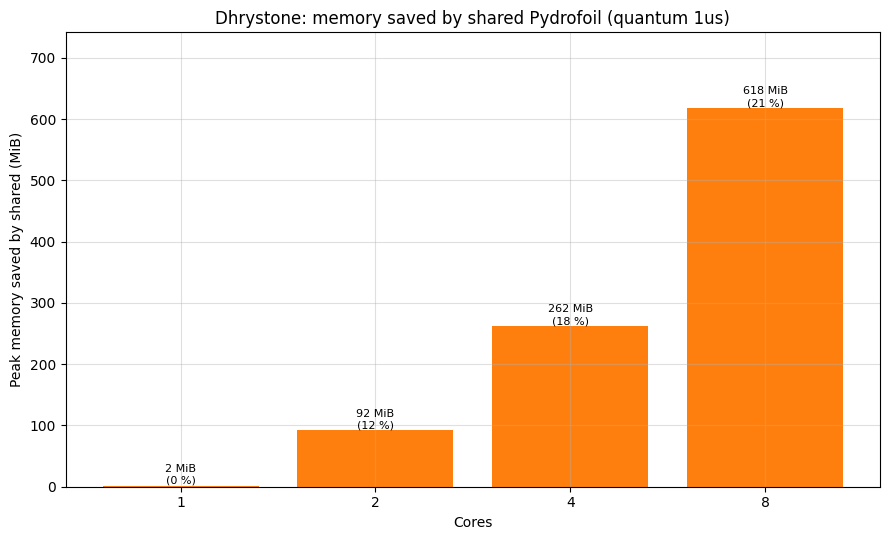

In [55]:
mean_mem = mem.groupby(['quantum', 'n_cores', 'mode'])['max_rss_mb'].mean().unstack('mode')
if not {'sync', 'sync, shared'} <= set(mean_mem.columns):
    print('need sync and sync, shared runs with max_rss_mb to compare')
else:
    saving = pd.DataFrame({
        'sync (MiB)': mean_mem['sync'],
        'shared (MiB)': mean_mem['sync, shared'],
        'saved (MiB)': mean_mem['sync'] - mean_mem['sync, shared'],
        'saved (%)': 100 * (1 - mean_mem['sync, shared'] / mean_mem['sync']),
    }).dropna()
    display(saving.round(1))
    for q in QUANTA:
        if q not in saving.index.get_level_values('quantum'):
            continue
        sq = saving.loc[q]
        fig, ax = plt.subplots()
        bars = ax.bar(range(len(sq.index)), sq['saved (MiB)'], color=COLORS['sync, shared'])
        ax.bar_label(bars, labels=['%.0f MiB\n(%.0f %%)' % (m, p)
                                   for m, p in zip(sq['saved (MiB)'], sq['saved (%)'])],
                     fontsize=8)
        ax.set_xticks(range(len(sq.index)))
        ax.set_xticklabels(sq.index)
        ax.set_xlabel('Cores')
        ax.set_ylabel('Peak memory saved by shared (MiB)')
        ax.set_ylim(top=sq['saved (MiB)'].max() * 1.2)
        ax.set_title('Dhrystone: memory saved by shared Pydrofoil (quantum %s)' % q)
        fig.tight_layout()
        if SAVE:
            path = PLOT_DIR / ('dhrystone_memory_saved_%s.png' % q)
            fig.savefig(path, dpi=200, bbox_inches='tight')
            print('wrote', path)
        plt.show()


## Summary table (mean MIPS)

In [56]:
summary = df.pivot_table(index=['quantum', 'n_cores'], columns='mode', values='mips', aggfunc='mean')
summary[[m for m in MODES if m in summary]].round(1)

mode             sync  sync, shared  async, rate 5
quantum n_cores                                   
1us     1        61.1          61.2           30.6
        2        63.2          53.2           48.0
        4        62.3          47.9           78.9
        8        60.6          41.9          103.5